In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

In [2]:
df=pd.read_csv('styles.csv')

In [3]:
image_folder=Path(r"e-commerce\images")

In [4]:
image_folder.exists()

True

In [5]:
df.shape

(44441, 10)

In [6]:
df.isnull().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

In [7]:
df.columns.tolist()

['id',
 'gender',
 'masterCategory',
 'subCategory',
 'articleType',
 'baseColour',
 'season',
 'year',
 'usage',
 'productDisplayName']

In [8]:
df.dtypes

id                      int64
gender                    str
masterCategory            str
subCategory               str
articleType               str
baseColour                str
season                    str
year                  float64
usage                     str
productDisplayName        str
dtype: object

In [9]:
image_extentions={'.jpg','.jpeg','.png','.webp','.bmp'}
image_paths=[path for path in image_folder.rglob('*')
             if path.is_file() and path.suffix.lower() in image_extentions]

In [10]:
print(len(image_paths))

44441


In [11]:
for path in image_paths[:10]:
    print(path)

e-commerce\images\10000.jpg
e-commerce\images\10001.jpg
e-commerce\images\10002.jpg
e-commerce\images\10003.jpg
e-commerce\images\10004.jpg
e-commerce\images\10005.jpg
e-commerce\images\10006.jpg
e-commerce\images\10007.jpg
e-commerce\images\10008.jpg
e-commerce\images\10009.jpg


In [12]:
valid_images=[]
invalid_images=[]
for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_images.append(path)
    except:
        invalid_images.append(path)
print(len(valid_images))
print(len(invalid_images))

44441
0


In [13]:
for path in valid_images[:5]:
    with Image.open(path) as img:
        print('filename:',path.name,'size:',img.size,'formate:',img.format)

filename: 10000.jpg size: (60, 80) formate: JPEG
filename: 10001.jpg size: (60, 80) formate: JPEG
filename: 10002.jpg size: (60, 80) formate: JPEG
filename: 10003.jpg size: (60, 80) formate: JPEG
filename: 10004.jpg size: (60, 80) formate: JPEG


In [14]:
image_folder=Path('e-commerce\images')
image_df=pd.DataFrame({
    'id':[ int(path.stem) for path in image_folder.glob("*.jpg") if path.stem.isdigit() ],
    'image_path':[str(path) for path in image_folder.glob('*.jpg') if path.stem.isdigit()]
})

<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:1: SyntaxWarning: invalid escape sequence '\i'
C:\Users\hites\AppData\Local\Temp\ipykernel_27996\2029282249.py:1: SyntaxWarning: invalid escape sequence '\i'
  image_folder=Path('e-commerce\images')


In [15]:
df["id"] = pd.to_numeric(df["id"], errors="coerce")
df = df.dropna(subset=["id"])
df["id"] = df["id"].astype(int)

merged_df = image_df.merge(df, on="id", how="left")
print("Total images:", len(image_df))
print("Images with metadata:", merged_df["productDisplayName"].notna().sum())
print("Images without metadata:", merged_df["productDisplayName"].isna().sum())

display(merged_df.head())

Total images: 44441
Images with metadata: 44434
Images without metadata: 7


,id,image_path,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,10000,e-commerce\images\10000.jpg,Women,Apparel,Bottomwear,Skirts,White,Summer,2011.0,Casual,Palm Tree Girls Sp Jace Sko White Skirts
1,10001,e-commerce\images\10001.jpg,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2011.0,Casual,Palm Tree Kids Girls Sp Jema Skt Blue Skirts
2,10002,e-commerce\images\10002.jpg,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2011.0,Casual,Palm Tree Kids Sp Jema Skt Blue Skirts
3,10003,e-commerce\images\10003.jpg,Women,Apparel,Topwear,Tshirts,White,Fall,2011.0,Sports,Nike Women As Nike Eleme White T-Shirt
4,10004,e-commerce\images\10004.jpg,Men,Apparel,Bottomwear,Shorts,Grey,Fall,2011.0,Sports,Nike Men As 7 Sw Temp Grey Shorts


In [16]:
notmetadata_df=merged_df[merged_df['productDisplayName'].isna()]

In [17]:
notmetadata_df

,id,image_path,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
17823,30991,e-commerce\images\30991.jpg,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017.0,NaN,NaN
17824,30992,e-commerce\images\30992.jpg,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017.0,NaN,NaN
26987,42863,e-commerce\images\42863.jpg,Women,Accessories,Bags,Clutches,Brown,Summer,2012.0,Casual,NaN
27002,42878,e-commerce\images\42878.jpg,Women,Accessories,Bags,Clutches,Maroon,Summer,2012.0,Casual,NaN
27228,43119,e-commerce\images\43119.jpg,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017.0,NaN,NaN
29403,45687,e-commerce\images\45687.jpg,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017.0,NaN,NaN
29409,45698,e-commerce\images\45698.jpg,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017.0,NaN,NaN


In [18]:
merged_df=merged_df.dropna(subset=['productDisplayName'])

In [19]:
final_df=merged_df.reset_index(drop=True)

In [47]:
final_df.head()

,id,image_path,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,10000,e-commerce\images\10000.jpg,Women,Apparel,Bottomwear,Skirts,White,Summer,2011.0,Casual,Palm Tree Girls Sp Jace Sko White Skirts
1,10001,e-commerce\images\10001.jpg,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2011.0,Casual,Palm Tree Kids Girls Sp Jema Skt Blue Skirts
2,10002,e-commerce\images\10002.jpg,Women,Apparel,Bottomwear,Skirts,Blue,Summer,2011.0,Casual,Palm Tree Kids Sp Jema Skt Blue Skirts
3,10003,e-commerce\images\10003.jpg,Women,Apparel,Topwear,Tshirts,White,Fall,2011.0,Sports,Nike Women As Nike Eleme White T-Shirt
4,10004,e-commerce\images\10004.jpg,Men,Apparel,Bottomwear,Shorts,Grey,Fall,2011.0,Sports,Nike Men As 7 Sw Temp Grey Shorts


In [20]:
final_df.shape

(44434, 11)

In [21]:
final_df.to_csv("e-commerce/final_image_dataset.csv",index=False)

In [22]:
from PIL import Image
from collections import Counter

In [23]:
image_sizes=Counter()
invalid_images=[]
for path in final_df['image_path']:
    try:
        with Image.open(path) as img:
            image_sizes[img.size]+=1
    except:
        invalid_images.append(path)
print('Most common image sizes',image_sizes.most_common(10))
print('invalid images are in total :',len(invalid_images))

Most common image sizes [((60, 80), 44411), ((53, 80), 10), ((60, 60), 5), ((60, 77), 2), ((60, 79), 2), ((54, 80), 2), ((60, 76), 1), ((60, 75), 1)]
invalid images are in total : 0


In [24]:
pip install torch torchvision scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.


In [25]:
pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [26]:
import torch
import torch.nn as nn

from torchvision import models, transforms
from PIL import Image
from tqdm.auto import tqdm
import numpy as np

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using:',device)
weights = models.ResNet50_Weights.DEFAULT
model=models.resnet50(weights=weights)
models.fc=nn.Identity()
model=model.to(device)
model.eval()
print('model loded sussfully')


c:\Users\hites\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


using: cuda
model loded sussfully


In [41]:
from torchvision import transforms

preprocess = weights.transforms()

print("Preprocessing ready!")

Preprocessing ready!


In [116]:
import torch.nn.functional as F
import numpy as np
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from PIL import Image

class ProductImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["image_path"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = self.transform(img.convert("RGB"))
        return image

preprocess = weights.transforms()

dataset = ProductImageDataset(final_df, preprocess)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

all_embeddings = []

with torch.inference_mode():
    for images in tqdm(loader, desc="Extracting embeddings"):
        images = images.to(device)

        features = model(images)

        # Normalize vectors for cosine similarity
        features = F.normalize(features, p=2, dim=1)

        all_embeddings.append(features.cpu().numpy())

embeddings = np.concatenate(all_embeddings, axis=0)

print("Embedding shape:", embeddings.shape)

Extracting embeddings: 100%|██████████| 1389/1389 [06:31<00:00,  3.55it/s]

Embedding shape: (44434, 1000)


In [ ]:
# from pathlib import Path
# import numpy as np

# output_folder = Path("image classfication project")
# output_folder.mkdir(exist_ok=True)

# np.save(output_folder / "embeddings.npy", embeddings)

# ---> use to save the file

In [117]:
embeddings

array([[-0.00933294,  0.00065641, -0.01159791, ..., -0.001179  ,
        -0.00558835, -0.04609484],
       [-0.01204281,  0.00901274, -0.01546276, ..., -0.00468825,
        -0.00782622, -0.05060105],
       [-0.00807554,  0.01366459, -0.01507846, ..., -0.00341711,
        -0.0060141 , -0.04930152],
       ...,
       [-0.01218035, -0.00075928, -0.00604093, ..., -0.00288148,
         0.01141841, -0.01625874],
       [-0.00502096, -0.00197562, -0.01055894, ...,  0.00447915,
         0.03278475,  0.01761939],
       [-0.00457885, -0.00529342, -0.02130175, ..., -0.00791344,
         0.00498444, -0.01976306]], shape=(44434, 1000), dtype=float32)

In [118]:
import numpy as np

def find_similar_images(image_index,top_n=5):
    image_emdedding=embeddings[image_index]
    score=embeddings @ image_emdedding
    score[image_index]=-1
    indices=np.argsort(score)[::-1][:top_n]
    results=final_df.iloc[indices].copy()
    results['similarity_score']=score[indices]
    return (results)

In [120]:
s=np.array([1,2,3,4])
i=np.array([0,3,2,1])
x=(s[i])
x[3]


np.int64(2)

In [119]:
find_similar_images(10)

,id,image_path,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,similarity_score
11168,2288,e-commerce\images\2288.jpg,Women,Apparel,Topwear,Tshirts,Black,Fall,2010.0,Sports,Nike Women Black T-shirt,0.894099
19070,32627,e-commerce\images\32627.jpg,Women,Apparel,Topwear,Tshirts,Purple,Summer,2012.0,Sports,Nike Women Miler Purple T-shirt,0.892466
22,10022,e-commerce\images\10022.jpg,Men,Apparel,Topwear,Tshirts,Blue,Fall,2011.0,Sports,Nike Men Blue Polo Tshirts,0.886021
15926,28525,e-commerce\images\28525.jpg,Men,Apparel,Topwear,Tshirts,Black,Summer,2012.0,Casual,Nike Men Man U Core Black T-shirt,0.884237
15934,28532,e-commerce\images\28532.jpg,Men,Apparel,Topwear,Tshirts,Black,Summer,2012.0,Sports,Nike Men Sphere Black T-shirt,0.883108


In [121]:
results = find_similar_images(image_index=10, top_n=5)

display(
    results[
        ["id", "productDisplayName", "image_path", "similarity_score"]
    ]
)

,id,productDisplayName,image_path,similarity_score
11168,2288,Nike Women Black T-shirt,e-commerce\images\2288.jpg,0.894099
19070,32627,Nike Women Miler Purple T-shirt,e-commerce\images\32627.jpg,0.892466
22,10022,Nike Men Blue Polo Tshirts,e-commerce\images\10022.jpg,0.886021
15926,28525,Nike Men Man U Core Black T-shirt,e-commerce\images\28525.jpg,0.884237
15934,28532,Nike Men Sphere Black T-shirt,e-commerce\images\28532.jpg,0.883108


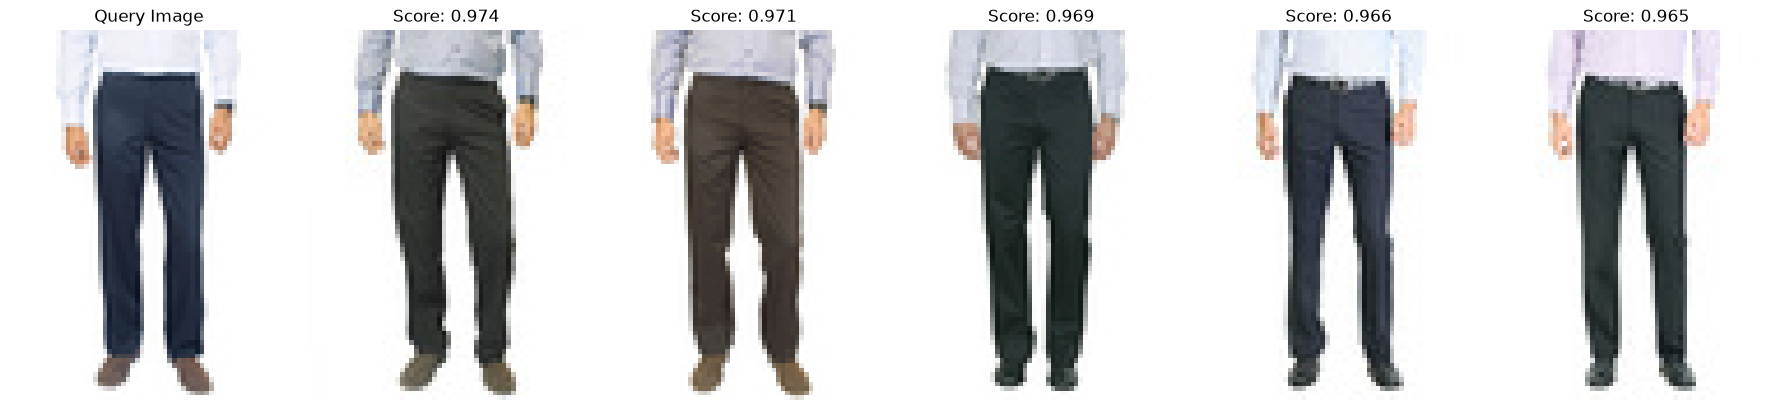

In [133]:
import matplotlib.pyplot as plt
from PIL import Image

query_index=1876
results=find_similar_images(query_index,top_n=5)
fig,axes=plt.subplots(1,6,figsize=(18,4))

with Image.open(final_df.iloc[query_index]['image_path']) as img:
    axes[0].imshow(img.convert('RGB'))
axes[0].set_title("Query Image")
axes[0].axis("off")

for ax,(_,rows) in zip(axes[1:],results.iterrows()):
    with Image.open(rows['image_path']) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"Score: {rows['similarity_score']:.3f}")
    ax.axis("off")


plt.tight_layout()
plt.show()
    



In [126]:
import numpy as np

embeddings = np.load(
    "embeddings.npy"
)

print("Shape:", embeddings.shape)
print("Data type:", embeddings.dtype)
print("Contains NaN:", np.isnan(embeddings).any())
print("Contains infinity:", np.isinf(embeddings).any())

Shape: (44434, 1000)
Data type: float32
Contains NaN: False
Contains infinity: False
